# Phase 1 — 1D Fundamentals: Advection, Diffusion and Burgers

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/phase1_fundamentals.ipynb)

*An overview of the first steps of the series, moved from somax's tutorial series.*

The geophysical models sesmax is built for are made of three elementary processes: transport (advection), smoothing (diffusion) and their nonlinear coupling. Each one already contains a numerical lesson that survives all the way up to the shallow-water and quasi-geostrophic models: the CFL limit of explicit advection, the much tighter stability limit of explicit diffusion, and the balance between steepening and smoothing that sets the grid Péclet number. This page develops the three in one dimension, where the physics is transparent and the models run in seconds {cite}`leveque2002finite,durran2010numerical`.

**What you'll learn:**

1. Why linear advection on a periodic ring is a pure phase shift, and what the CFL number controls
2. Why explicit diffusion is limited by $\Delta t \lesssim \Delta x^2 / (2 \nu)$, not by $\Delta x$
3. How the nonlinear Burgers flux steepens a smooth wave into a front, and how viscosity arrests it

### Symbols

The page uses the classic CFD letters. Everything is nondimensional, and $x$ is the spatial coordinate.

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $x \in [0, L_x)$ | spatial coordinate | $\mathbb{R}$ |
| $t$ | time | $\mathbb{R}$ |
| $u(x, t)$ | the field | $\mathbb{R}$ |
| $u_0(x)$ | initial condition | $\mathbb{R}$ |
| $c$, $\nu$ | wave speed and viscosity | $\mathbb{R}$, $\mathbb{R}_{>0}$ |
| $U$ | velocity scale, the peak of $\lvert u_0 \rvert$ | $\mathbb{R}_{>0}$ |
| $L_x$ | domain length | $\mathbb{R}_{>0}$ |
| $N_{\Omega_x}$, $N_T$ | number of interior grid cells and of saved snapshots | count |
| $\Delta x = L_x / N_{\Omega_x}$, $\Delta t$ | grid spacing and time step | $\mathbb{R}_{>0}$ |
| $\sigma_0$, $\sigma(t)$ | initial and current Gaussian width | $\mathbb{R}_{>0}$ |
| $\mathrm{CFL}$, $\mathrm{Pe}_\Delta$ | Courant number and grid Péclet number | $\mathbb{R}_{\ge 0}$ |

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

In [2]:
import diffrax as dfx
import einx
import jax.numpy as jnp
import matplotlib.pyplot as plt

import sesmax_core.testing as sxt

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Linear advection: transport without distortion

The 1D linear advection equation moves a field $u(x, t)$ at constant speed $c$ without changing its shape,

$$\frac{\partial u}{\partial t} + c \frac{\partial u}{\partial x} = 0$$ (p1-advection)

with exact solution $u(x, t) = u_0(x - c t)$, the initial profile translated rigidly. On a periodic domain the solution returns to its start after one transit time $L_x / c$. The numerical challenge is that an explicit scheme can only see information within a few cells per step, so the time step is bounded by the Courant–Friedrichs–Lewy (CFL) condition

$$\mathrm{CFL} = \frac{c \Delta t}{\Delta x} \le \mathrm{CFL}_\text{max}$$ (p1-cfl)

where $\mathrm{CFL}_\text{max}$ is an order-one constant set by the time integrator. Above it the scheme is unstable; well below it, numerical diffusion smears the profile. Equation {eq}`p1-cfl` is the one-dimensional ancestor of the gravity-wave CFL that governs every shallow-water run.

We advect a smooth Gaussian pulse one full transit around a periodic ring. The exact solution returns it to the start, so whatever differs is the numerical scheme. [Step 1](step01_linear_convection_1d.ipynb) works through this model in detail.

In [4]:
# Shapes: N_Ωx = 200 interior cells; arrays carry N_Ωx + 2 = 202 with the ghosts

interior = slice(1, -1)
pulse_centre = 0.3
pulse_width = 0.05
wave_speed = 1.0
advection_step = 2.0e-3

# today (sesmax_core)
advection_model = sxt.LinearConvection1D.create(nx=200, Lx=1.0, c=wave_speed)

# xₙ = n Δx
advection_position = jnp.arange(advection_model.grid.Nx) * advection_model.grid.dx
# zₙ = (xₙ − μ₀) / σ₀
standardised = (advection_position - pulse_centre) / pulse_width  # → (N_Ωx + 2,)
# u₀(x) = exp(−z² / 2)
initial_pulse = jnp.exp(-0.5 * standardised**2)  # → (N_Ωx + 2,)
# today (sesmax_core)
advection_state = sxt.LinearConvection1DState(u=initial_pulse)
advection_state = advection_model.apply_boundary_conditions(advection_state)

# today (sesmax_core, diffrax)
# One full transit of the periodic domain: t = L_x / c
advection_solution = advection_model.integrate(  # u → (1, N_Ωx + 2)
    advection_state, t0=0.0, t1=1.0, dt=advection_step
)
final_pulse = advection_solution.ys.u[-1]  # → (N_Ωx + 2,)

# CFL = c Δt / Δx
courant_number = wave_speed * advection_step / advection_model.grid.dx  # → ()
# max u(x, L_x / c)
final_peak = jnp.max(final_pulse[interior])  # → ()
print(f"CFL = {float(courant_number):.3f}")
print(f"Peak after one transit: {float(final_peak):.3f} (exact: 1)")

CFL = 0.400
Peak after one transit: 0.992 (exact: 1)


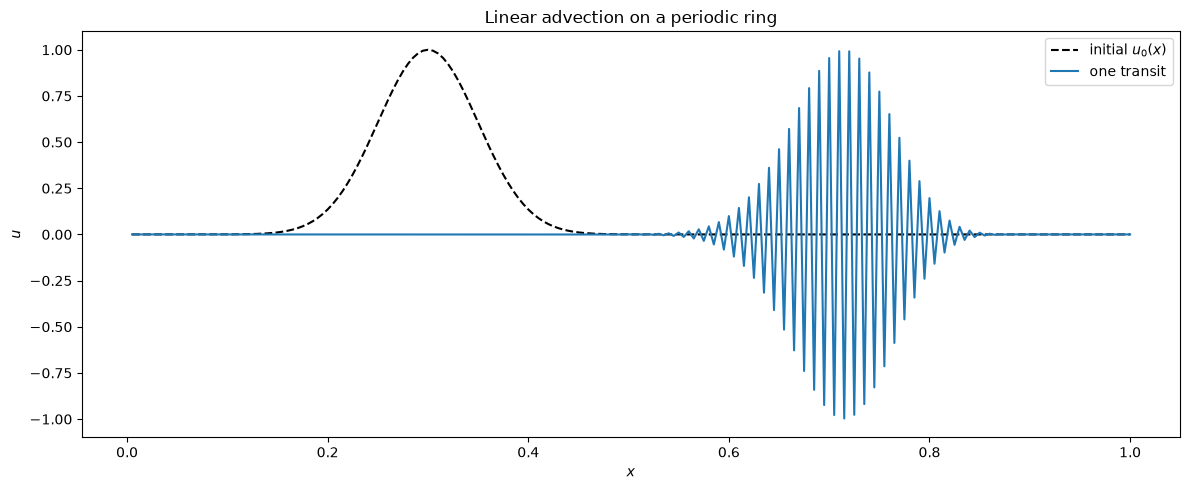

In [5]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    advection_position[interior],
    initial_pulse[interior],
    "k--",
    label="initial $u_0(x)$",
)
ax.plot(advection_position[interior], final_pulse[interior], "C0", label="one transit")
ax.set_xlabel("$x$")
ax.set_ylabel("$u$")
ax.set_title("Linear advection on a periodic ring")
ax.legend()
plt.tight_layout()
plt.show()

The dashed curve is the initial condition and the solid curve is the numerical solution after returning to its start. The CFL number is well inside the stable range, so the pulse comes back to where it started; the small drop in the printed peak is the numerical error of the centred flux and the Runge–Kutta integrator over one revolution.

## 2. Diffusion: smoothing and the parabolic time-step limit

The 1D diffusion (heat) equation spreads a field at a rate set by the viscosity $\nu$,

$$\frac{\partial u}{\partial t} = \nu \frac{\partial^2 u}{\partial x^2}$$ (p1-diffusion)

A Gaussian stays Gaussian with its variance growing linearly in time, so a blob of initial width $\sigma_0$ has width $\sigma(t) = \sqrt{\sigma_0^2 + 2 \nu t}$ and peak $\sigma_0 / \sigma(t)$. The crucial numerical fact is that an explicit discretisation of {eq}`p1-diffusion` is stable only for

$$\frac{\nu \Delta t}{\Delta x^2} \le \frac{1}{2}$$ (p1-diffusion-cfl)

a limit that scales with $\Delta x^2$, not with $\Delta x$. Refining the grid by two therefore demands a four-fold smaller step, which is why stiff diffusion is the term to tag `implicit` for an IMEX integration. Details are in [Step 3](step03_diffusion_1d.ipynb).

In [6]:
# Shapes: N_Ωx = 200 interior cells; arrays carry N_Ωx + 2 = 202 with the ghosts;
# N_T = 5 saved snapshots

blob_centre = 0.5
blob_width = 0.04
viscosity = 2.0e-3
diffusion_step = 5.0e-4
diffusion_end = 8.0

# today (sesmax_core)
diffusion_model = sxt.Diffusion1D.create(nx=200, Lx=1.0, nu=viscosity)

# xₙ = n Δx
diffusion_position = jnp.arange(diffusion_model.grid.Nx) * diffusion_model.grid.dx
# zₙ = (xₙ − μ₀) / σ₀
standardised = (diffusion_position - blob_centre) / blob_width  # → (N_Ωx + 2,)
# u₀(x) = exp(−z² / 2)
initial_blob = jnp.exp(-0.5 * standardised**2)  # → (N_Ωx + 2,)
# today (sesmax_core)
diffusion_state = sxt.Diffusion1DState(u=initial_blob)
diffusion_state = diffusion_model.apply_boundary_conditions(diffusion_state)

# ν Δt / Δx²
diffusion_number = viscosity * diffusion_step / diffusion_model.grid.dx**2  # → ()
print(f"Diffusion number nu dt / dx^2 = {float(diffusion_number):.3f} (limit 0.5)")

# tₖ = k t₁ / (N_T − 1)
diffusion_times = jnp.linspace(0.0, diffusion_end, 5)  # → (N_T,)
# today (sesmax_core, diffrax)
diffusion_solution = diffusion_model.integrate(  # u → (N_T, N_Ωx + 2)
    diffusion_state,
    t0=0.0,
    t1=diffusion_end,
    dt=diffusion_step,
    saveat=dfx.SaveAt(ts=diffusion_times),
    max_steps=20_000,
)

# ∑ₙ u(xₙ, t) Δx over the interior cells, for each saved time
interior_blob = diffusion_solution.ys.u[:, interior]  # → (N_T, N_Ωx)
blob_area = einx.sum("t [x] -> t", interior_blob) * diffusion_model.grid.dx  # → (N_T,)
# σ(t) = √(σ₀² + 2νt)
width_at_two = jnp.sqrt(blob_width**2 + 2.0 * viscosity * diffusion_times[1])  # → ()
# maxₙ u(xₙ, t₁) against σ₀ / σ(t₁)
numerical_peak = jnp.max(interior_blob[1])  # → ()
exact_peak = blob_width / width_at_two  # → ()
print(f"Area at t = 0: {float(blob_area[0]):.6f}, at t = 8: {float(blob_area[-1]):.6f}")
print(f"Peak at t = 2: {float(numerical_peak):.4f}, exact {float(exact_peak):.4f}")

Diffusion number nu dt / dx^2 = 0.040 (limit 0.5)


Area at t = 0: 0.100265, at t = 8: 0.100265
Peak at t = 2: 0.4084, exact 0.4082


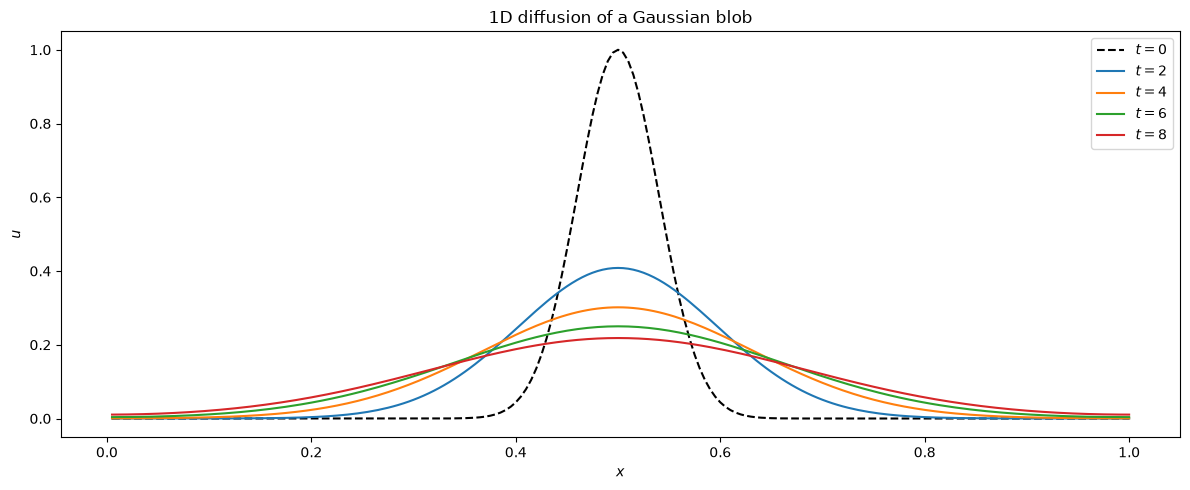

In [7]:
fig, ax = plt.subplots(figsize=(12, 5))
for snapshot, snapshot_time in enumerate(diffusion_times):
    style = "k--" if snapshot == 0 else f"C{snapshot - 1}"
    ax.plot(
        diffusion_position[interior],
        interior_blob[snapshot],
        style,
        label=f"$t={float(snapshot_time):.0f}$",
    )
ax.set_xlabel("$x$")
ax.set_ylabel("$u$")
ax.set_title("1D diffusion of a Gaussian blob")
ax.legend()
plt.tight_layout()
plt.show()

Each curve is a later time: the peak drops and the profile widens while the printed area stays the same, the hallmark of diffusion on a periodic domain.

## 3. Burgers: nonlinear steepening meets viscous smoothing

The viscous Burgers equation couples nonlinear self-advection to diffusion,

$$\frac{\partial u}{\partial t} + u \frac{\partial u}{\partial x} = \nu \frac{\partial^2 u}{\partial x^2}$$ (p1-burgers)

and is the canonical one-dimensional caricature of the Navier–Stokes balance between inertia and viscosity {cite}`burgers1948mathematical`. Where $u$ is large the wave moves faster, so a smooth profile steepens on its leading edge; the viscous term resists, and the two balance in a thin front of width of order $\nu / U$. The relevant dimensionless number is the grid Péclet number $\mathrm{Pe}_\Delta = U \Delta x / \nu$: when it exceeds about 2, the front is under-resolved and the advection scheme controls the spurious oscillations. [Step 4](step04_burgers_1d.ipynb) has the details.

In [8]:
# Shapes: N_Ωx = 256 interior cells; arrays carry N_Ωx + 2 = 258 with the ghosts;
# N_T = 4 saved snapshots

burgers_viscosity = 2.0e-3
burgers_end = 0.24

# today (sesmax_core)
burgers_model = sxt.Burgers1D.create(nx=256, Lx=1.0, nu=burgers_viscosity)

# xₙ = n Δx
burgers_position = jnp.arange(burgers_model.grid.Nx) * burgers_model.grid.dx
# u₀(x) = sin(2π x)
initial_sine = jnp.sin(2.0 * jnp.pi * burgers_position)  # → (N_Ωx + 2,)
# today (sesmax_core)
burgers_state = sxt.Burgers1DState(u=initial_sine)
burgers_state = burgers_model.apply_boundary_conditions(burgers_state)

# tₖ = k t₁ / (N_T − 1)
burgers_times = jnp.linspace(0.0, burgers_end, 4)  # → (N_T,)
# today (sesmax_core, diffrax)
burgers_solution = burgers_model.integrate(  # u → (N_T, N_Ωx + 2)
    burgers_state,
    t0=0.0,
    t1=burgers_end,
    dt=5.0e-4,
    saveat=dfx.SaveAt(ts=burgers_times),
)

# Pe_Δ = U Δx / ν
peak_speed = jnp.max(jnp.abs(initial_sine))  # → ()
grid_peclet = peak_speed * burgers_model.grid.dx / burgers_viscosity  # → ()
print(f"Grid Peclet number U dx / nu = {float(grid_peclet):.2f}")

Grid Peclet number U dx / nu = 1.95


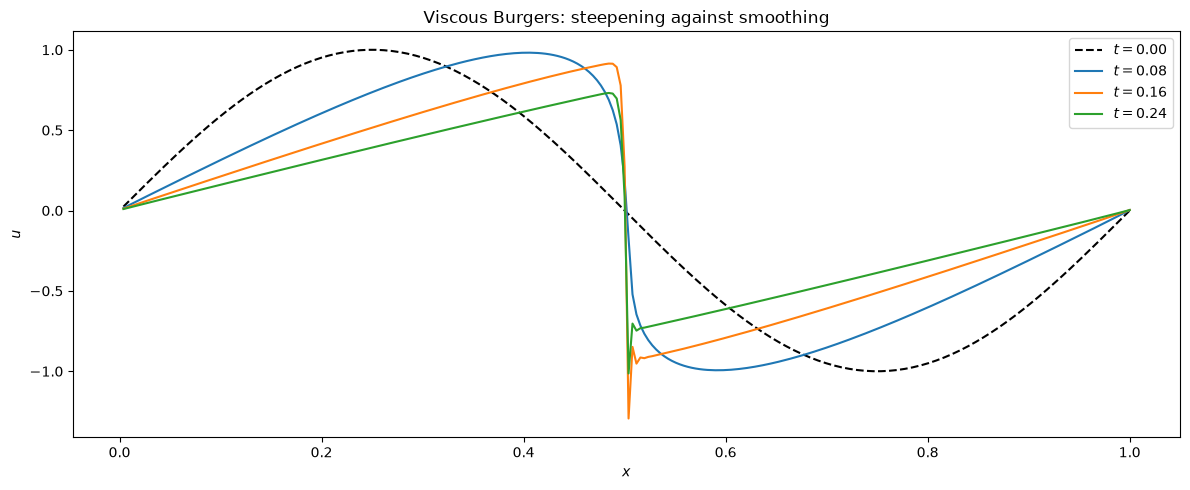

In [9]:
fig, ax = plt.subplots(figsize=(12, 5))
for snapshot, snapshot_time in enumerate(burgers_times):
    style = "k--" if snapshot == 0 else f"C{snapshot - 1}"
    ax.plot(
        burgers_position[interior],
        burgers_solution.ys.u[snapshot, interior],
        style,
        label=f"$t={float(snapshot_time):.2f}$",
    )
ax.set_xlabel("$x$")
ax.set_ylabel("$u$")
ax.set_title("Viscous Burgers: steepening against smoothing")
ax.legend()
plt.tight_layout()
plt.show()

The compressive half of the sine wave steepens toward a near-shock as the nonlinear flux compresses it, and viscosity holds the front at a finite width instead of letting it break.

:::{note} Known issue
The model's nonlinear term is currently twice the documented one, because its flux is $u^2$ rather than $u^2 / 2$, so this wave steepens at twice the rate the equation predicts. The undershoot behind the front is also numerical. Both are tracked in [issue #65](https://github.com/jejjohnson/sesmax/issues/65), and this page will be re-executed when it is fixed.
:::

## Summary

| Process | Equation | Explicit step limit |
| --- | --- | --- |
| Advection | {eq}`p1-advection` | hyperbolic, $c \Delta t / \Delta x$ of order one |
| Diffusion | {eq}`p1-diffusion` | parabolic, $\nu \Delta t / \Delta x^2 \le 1/2$ |
| Burgers | {eq}`p1-burgers` | both, plus grid-Péclet resolution of the front |

- Linear advection is a pure translation, and the CFL number {eq}`p1-cfl` bounds the explicit step. It is the ancestor of the gravity-wave CFL in the shallow-water models.
- Explicit diffusion carries the far tighter parabolic limit {eq}`p1-diffusion-cfl`, which is why the term algebra offers an IMEX path for the stiff Laplacian.
- Burgers couples the two: the nonlinear flux steepens, viscosity smooths, and the grid Péclet number decides whether the front is resolved.

**Next:** [Phase 2](phase2_spatial.ipynb) lifts these processes into two dimensions and adds the elliptic (Poisson) problem that ties velocity to vorticity.